In [ ]:
import zipfile
zipfile.ZipFile('archive.zip').extractall()
print("Done")


Done


In [ ]:
import pandas as pd
import os
print(os.listdir())

df = pd.read_csv('supermarket_sales.csv')
print(df.shape)
df.head()

['.config', 'archive.zip', 'supermarket_sales.csv', 'sample_data']
(1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
# 1. Check shape, columns, missing values
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nData types:")
print(df.dtypes)

Shape: (1000, 17)

Columns:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Missing values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Data types:
Invoice ID                  object
Branch                      object
City                        object
Customer type               object
Gender                      object
Product line                object
Unit price       

In [ ]:
print(df['Product line'].value_counts())
print("\n")
print(df['City'].value_counts())
print("\n")
print(df['Payment'].value_counts())

Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64


City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64


Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


In [ ]:
print(df.groupby('Product line')['Total'].sum().sort_values(ascending=False))
print("\n")
print(df.groupby('City')['Total'].sum().sort_values(ascending=False))
print("\n")
print(df.groupby('Payment')['Total'].sum().sort_values(ascending=False))

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64


City
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: Total, dtype: float64


Payment
Cash           112206.570
Ewallet        109993.107
Credit card    100767.072
Name: Total, dtype: float64


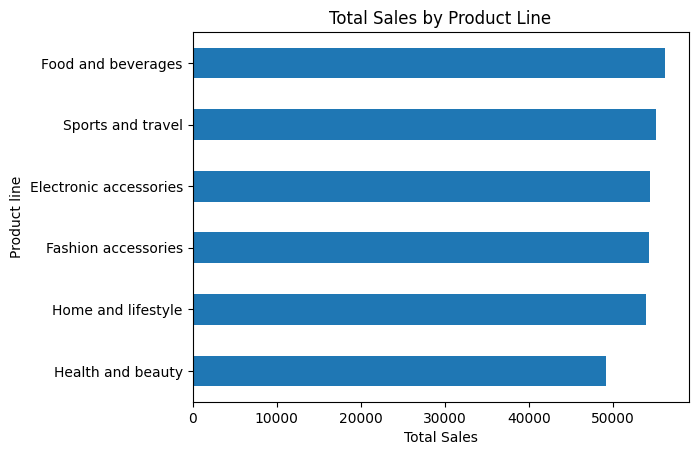

In [ ]:
import matplotlib.pyplot as plt

df.groupby('Product line')['Total'].sum().sort_values().plot(kind='barh')
plt.title('Total Sales by Product Line')
plt.xlabel('Total Sales')
plt.show()

In [ ]:
print(df.groupby('Gender')['Total'].sum())
print("\n")
print(df.groupby('Customer type')['Total'].sum())
print("\n")
print(df['Rating'].describe())

Gender
Female    167882.925
Male      155083.824
Name: Total, dtype: float64


Customer type
Member    164223.444
Normal    158743.305
Name: Total, dtype: float64


count    1000.00000
mean        6.97270
std         1.71858
min         4.00000
25%         5.50000
50%         7.00000
75%         8.50000
max        10.00000
Name: Rating, dtype: float64


In [ ]:
print("EDA Summary - Supermarket Sales")
print("Total sales:", df['Total'].sum())
print("Average sale:", df['Total'].mean())
print("Best product by money:", df.groupby('Product line')['Total'].sum().idxmax())
print("Best city by money:", df.groupby('City')['Total'].sum().idxmax())

EDA Summary - Supermarket Sales
Total sales: 322966.749
Average sale: 322.966749
Best product by money: Food and beverages
Best city by money: Naypyitaw


In [ ]:
print(df['Payment'].value_counts())
print(df.groupby('Gender')['Total'].sum())
print(df.groupby('Customer type')['Total'].sum())

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64
Gender
Female    167882.925
Male      155083.824
Name: Total, dtype: float64
Customer type
Member    164223.444
Normal    158743.305
Name: Total, dtype: float64


<Axes: xlabel='City'>

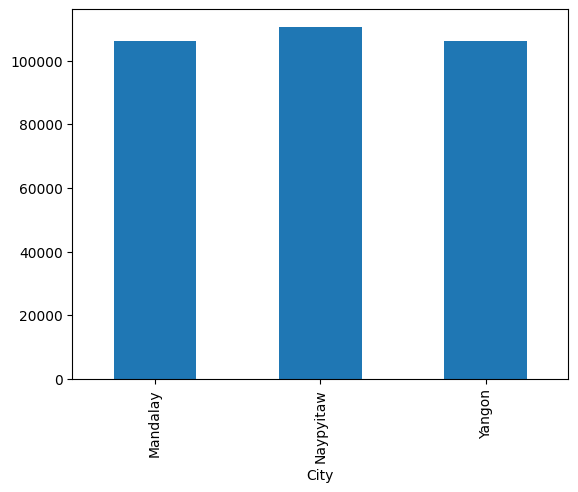

In [ ]:
df.groupby('City')['Total'].sum().plot(kind='bar')

Conclusion

Food and beverages is the best-selling product line and Naypyitaw is the best city by total sales.
Female customers contributed more than male customers, and members contributed more than normal customers.
Most customers paid with Ewallet (345) and Cash (344), while Credit card (311) was the least used.